# Read JEDI electron data and make energy and pitch-angle spectra

In [1]:
import datetime as dt
import numpy as np
from matplotlib import pyplot as plt

from junopy import config
from junopy import index
from junopy import jedi
from junopy import utils

import matplotlib as mpl
from matplotlib import pyplot as plt
from matplotlib import colors
from matplotlib import dates

config.ConfigVars.set_root(".junodata")

Importing Library
done


In [2]:
import logging
logger = logging.getLogger(__name__)

logging.basicConfig(level=logging.INFO)

Reading the JEDI data is easy using `jedi.JediData`. However, it is much easier to merge data from different JEDI sensors to make energy and pitch-angle spectra. This is done as follows - 

In [3]:
start = dt.datetime(2020, 1, 1, 2)
stop = dt.datetime(2020, 1, 1, 23)

jedi_index = index.IndexFile(dataset='jedi')
jedi_files = jedi_index.get_files_between_dates(
    start, 
    stop, 
    sid="ERSESP",
    do_download=True,   # Set to False after first run.
    get_label=False
)

# If the JEDI file is in ASCII format, reading it via junopy for the first 
# time will convert it into .hdf5
for fname in jedi_files:
    if fname.exists():
        _ = jedi.JediData(filename=fname, do_save_only=True)
    
jedi_files = [fname.with_suffix(".hdf5") for fname in jedi_files]

# Read all available JEDI data into a list.
jedi_data_list  = [
    jedi.JediData(
        filename=jf,
        species="ELECTRON",
        start=start,
        stop=stop,
    ) for jf in jedi_files
]
print(jedi_data_list)

merged_data = jedi.merge_multiple_jedi_data(
    jedi_data_list, 
    min_energy=20, 
    max_energy=2e3, 
    cadence=dt.timedelta(seconds=60), 
    num_pitchangle_bins=40, 
)


[<junopy.jedi.read.JediData object at 0x7f334434d6d0>, <junopy.jedi.read.JediData object at 0x7f335cb37170>, <junopy.jedi.read.JediData object at 0x7f32a7109880>]


In [4]:
# Example of raw JEDI data

In [5]:
jedi_data_list[0].data_raw

,UTC,ETStart,ETLookDirection,ETEnd,Duration,SectorDeadTime,LargePixel,SCLKStart,SCLKLookDirection,SCLKEnd,...,T4EXC05 SIGMA,T4EXC06 SIGMA,T4EXC07 SIGMA,T5EXC01 SIGMA,T5EXC02 SIGMA,T5EXC03 SIGMA,T5EXC04 SIGMA,T5EXC05 SIGMA,T5EXC06 SIGMA,T5EXC07 SIGMA
time,,,,,,,,,,,,,,,,,,,,,
2020-01-01 02:00:19.295814,2020-01-01T02:00:19,6.311159e+08,6.311161e+08,6.311162e+08,25.311167,0.597,False,5/0631116174:52756,5/0631116327:61574,5/0631116481:04784,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2020-01-01 02:00:21.826897,2020-01-01T02:00:21,6.311159e+08,6.311161e+08,6.311162e+08,25.311167,0.597,False,5/0631116177:22025,5/0631116330:30843,5/0631116483:39584,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2020-01-01 02:00:24.357981,2020-01-01T02:00:24,6.311159e+08,6.311161e+08,6.311162e+08,25.311167,0.597,False,5/0631116179:56831,5/0631116333:00112,5/0631116486:08847,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2020-01-01 02:00:26.889064,2020-01-01T02:00:26,6.311159e+08,6.311161e+08,6.311162e+08,25.311167,0.597,False,5/0631116182:26100,5/0631116335:34918,5/0631116488:43647,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2020-01-01 02:00:29.420147,2020-01-01T02:00:29,6.311159e+08,6.311161e+08,6.311163e+08,25.311167,0.597,False,5/0631116184:60905,5/0631116338:04187,5/0631116491:12911,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2020-01-01 22:56:03.412563,2020-01-01T22:56:03,6.311913e+08,6.311914e+08,6.311916e+08,25.310750,0.597,False,5/0631191519:01088,5/0631191672:09832,5/0631191825:18570,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2020-01-01 22:56:05.943897,2020-01-01T22:56:05,6.311913e+08,6.311914e+08,6.311916e+08,25.310750,0.597,False,5/0631191521:35893,5/0631191674:44653,5/0631191827:53381,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2020-01-01 22:56:08.475230,2020-01-01T22:56:08,6.311913e+08,6.311914e+08,6.311916e+08,25.310750,0.597,False,5/0631191524:05163,5/0631191677:13939,5/0631191830:22655,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


The data for each SSD is stored separately, in case you need it.

In [6]:
jedi_data_list[0].ssd_data[0].data

,T0EXC01 FLUX,T0EXC02 FLUX,T0EXC03 FLUX,T0EXC04 FLUX,T0EXC05 FLUX,T0EXC06 FLUX,T0EXC07 FLUX
time,,,,,,,
2020-01-01 02:00:19.295814,185317.240835,0.000000,39.525705,44.200789,0.000000,6.304714,12.381546
2020-01-01 02:00:21.826897,134776.115515,250.650703,0.000000,0.000000,0.000000,6.304711,6.190770
2020-01-01 02:00:24.357981,134776.115515,0.000000,39.525688,22.100385,13.049751,6.304711,6.190770
2020-01-01 02:00:26.889064,134776.115515,125.325351,39.525688,22.100385,0.000000,18.914133,0.000000
2020-01-01 02:00:29.420147,168470.237577,250.650841,39.525710,22.100397,26.099516,6.304714,6.190774
...,...,...,...,...,...,...,...
2020-01-01 22:56:03.412563,235858.332617,125.325421,0.000000,44.200794,0.000000,6.304714,0.000000
2020-01-01 22:56:05.943897,185317.199839,0.000000,0.000000,22.100389,13.049754,12.609425,0.000000
2020-01-01 22:56:08.475230,117929.114125,0.000000,0.000000,22.100387,13.049752,31.523558,6.190771


The energy channels are stored in the `metadata`.

In [7]:
jedi_data_list[0].metadata.head()

,Channel,Elow,Ehigh,Particle,Geff
0,T0EXC01,17.845915,25.942676,ELECTRON,NaN
1,T0EXC02,26.695667,42.009203,ELECTRON,NaN
2,T0EXC03,42.782920,73.119106,ELECTRON,NaN
3,T0EXC04,73.896946,127.671284,ELECTRON,NaN
4,T0EXC05,128.426943,221.786450,ELECTRON,NaN


# Plot the energy and pitch-angle spectra using the provided methods.

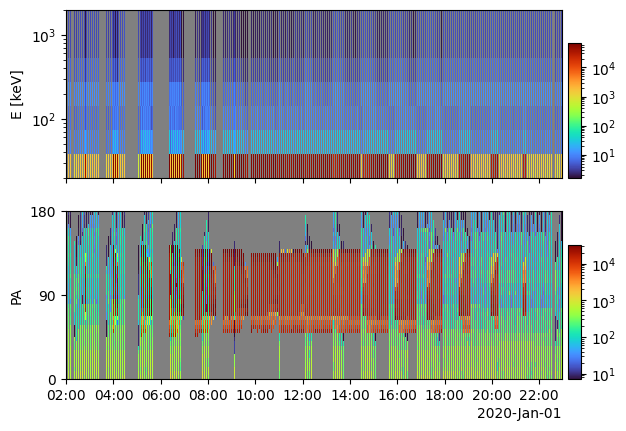

In [8]:
fig, axs = plt.subplots(2, 1, gridspec_kw=dict(wspace=0.3))

jedi.plot.plot_timeseries_spectra(
    merged_data.energy_spectra,
    merged_data.energy_bins,
    axs[0],
)
jedi.plot.plot_timeseries_spectra(
    merged_data.pitchangle_spectra,
    merged_data.pitchangle_bins,
    axs[1],
)

        
axs[0].xaxis.set_major_formatter(dates.ConciseDateFormatter(axs[0].xaxis.get_major_locator()))
axs[1].xaxis.set_major_formatter(dates.ConciseDateFormatter(axs[1].xaxis.get_major_locator()))
axs[0].set_yscale("log")
axs[0].set_ylabel("E [keV]")
axs[1].set_ylabel("PA")
axs[1].set_yticks([0, 90, 180])
for a in axs:
    a.label_outer()
plt.show()

Well, this isn't the best time to be looking at JEDI data, but hopefully you get the idea.